In [1]:
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

tf.keras.utils.set_random_seed(42)

data = np.load("../data/sign_mnist_prepared.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}

print(X_train.shape, X_test.shape)

(27455, 28, 28, 1) (7172, 28, 28, 1)


In [2]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train.reshape(len(X_train), -1), y_train)
y_pred_dummy = dummy.predict(X_test.reshape(len(X_test), -1))

res_dummy = {
    "accuracy": accuracy_score(y_test, y_pred_dummy),
    "f1_macro": f1_score(y_test, y_pred_dummy, average="macro"),
}
print("DummyClassifier :", res_dummy)
print("Prédiction aléatoire théorique : accuracy =", round(1 / 24, 4))

DummyClassifier : {'accuracy': 0.020078081427774678, 'f1_macro': 0.0016402405686167304}
Prédiction aléatoire théorique : accuracy = 0.0417


Tres bas , avant apprentissage : 4%

In [3]:
def build_simple_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(24, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_simple_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

TRAINING

In [4]:
start = time.time()
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    verbose=1,
)
print(f"Temps d'entraînement : {time.time() - start:.0f} s")


Epoch 1/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.6269 - loss: 1.2745 - val_accuracy: 0.8927 - val_loss: 0.3441
Epoch 2/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9551 - loss: 0.1779 - val_accuracy: 0.9958 - val_loss: 0.0533
Epoch 3/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9974 - loss: 0.0329 - val_accuracy: 0.9998 - val_loss: 0.0144
Epoch 4/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9995 - loss: 0.0106 - val_accuracy: 1.0000 - val_loss: 0.0058
Epoch 5/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9999 - loss: 0.0045 - val_accuracy: 0.9998 - val_loss: 0.0033
Epoch 6/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 7/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 8/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 1.0000 - loss: 9.9449e-04 - 

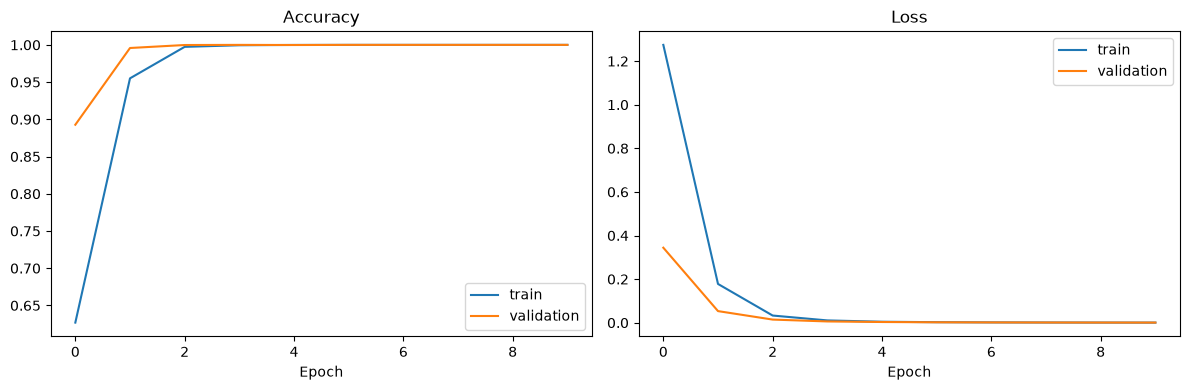

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

In [6]:
proba = model.predict(X_test, verbose=0)
y_pred_cnn = proba.argmax(axis=1)

res_cnn = {
    "accuracy": accuracy_score(y_test, y_pred_cnn),
    "precision_macro": precision_score(y_test, y_pred_cnn, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred_cnn, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred_cnn, average="macro"),
}
print("CNN simple :", {k: round(v, 4) for k, v in res_cnn.items()})

CNN simple : {'accuracy': 0.9123, 'precision_macro': 0.9104, 'recall_macro': 0.9087, 'f1_macro': 0.9071}


In [7]:
one = X_test[:1]
model.predict(one, verbose=0)  # échauffement
t0 = time.time()
for _ in range(50):
    model.predict(one, verbose=0)
print(f"Temps moyen par image : {(time.time() - t0) / 50 * 1000:.1f} ms")

Temps moyen par image : 124.6 ms


In [8]:
import os
os.makedirs("../docs", exist_ok=True)

results = {"dummy": res_dummy, "cnn_simple": res_cnn}
with open("../docs/baseline_results.json", "w") as f:
    json.dump(results, f, indent=2)

model.save("../data/cnn_simple.keras")